# MAI-Image-2.6-Flash

<p align="center">
  <img src="../../.github/images/banners/mai-image-2.6-flash.png" alt="MAI-Image-2.6-Flash: draft fast, finish on MAI-Image-2.6" width="900" />
</p>

The same image features as MAI-Image-2.6, faster and cheaper, from Microsoft AI on Microsoft Foundry.

| | |
|---|---|
| Released | 2026-08-10 (announced; generally available on Foundry by October 2026) |
| Publisher | Microsoft AI |
| Capability | [Image Generation](../../3-primers/image-generation.md) |
| Model card | [MAI-Image-2.6-Flash](https://ai.azure.com/catalog/models/MAI-Image-2.6-Flash) |
| Announcement | [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/) |
| Docs | [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) |
| Deployment | Global Standard, pay-as-you-go |
| Modes | Generate from text · edit with 1–5 reference images · web grounding · auto aspect ratio |
| Picture size | Each side at least 768 px, up to 2,359,296 pixels in total (1536 × 1536) |
| Prompt | Up to 32,000 tokens, English |
| Rate limit | 6 to 36 requests a minute, by quota tier |
| Pricing | [MAI model pricing](https://aka.ms/MAIModelPricing) |
| Compared with | [MAI-Image-2.6](../mai-image-2.6/): same features, sizes, prompt length, and rate limits |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT` (or `MAI_IMAGE_ENDPOINT`), `AZURE_MAI_IMAGE_26_DEPLOYMENT`, `AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT`, `MAI_IMAGE_REQUESTS_PER_MINUTE`, `DEMO_MODE` |

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Do we pay for the best model every time, or is Flash good enough, and for which jobs?"*

Flash and MAI-Image-2.6 share every feature, so the real questions are speed, cost, and finish. We make routine product shots on Flash, run a blind taste test against MAI-Image-2.6, measure both, and try the pattern we'd suggest to most teams: draft on Flash, finish on MAI-Image-2.6.

## What We Will Do

- Make five studio product shots on Flash, the routine work it's built for
- Judge Flash against MAI-Image-2.6 blind, then measure the time each takes
- Draft six ad concepts on Flash and finish the favorite on MAI-Image-2.6

> Run each cell with **Shift + Enter**. Guess first: before each reveal, predict which model made which picture.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows pictures saved in `examples/` (some point at the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/data/generated/images/)) and makes no Azure calls.

**Running it live?** We need **MAI-Image-2.6-Flash** and **MAI-Image-2.6** deployments in our Foundry project, a sign-in with a Foundry role (run `az login`; we use keyless Microsoft Entra ID tokens), and `DEMO_MODE=live` in `.env`. Our pictures go to `output/`, which git ignores, and replay shows them first from then on. Live mode never writes to the scenario folder.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "mai_image.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = (os.getenv("MAI_IMAGE_ENDPOINT") or os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "")).strip()
HERO = os.getenv("AZURE_MAI_IMAGE_26_DEPLOYMENT", "MAI-Image-2.6").strip()
FLASH = os.getenv("AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT", "MAI-Image-2.6-Flash").strip()
RPM = int(os.getenv("MAI_IMAGE_REQUESTS_PER_MINUTE", "6"))

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("No endpoint in .env. Set MAI_IMAGE_ENDPOINT (or MICROSOFT_FOUNDRY_ENDPOINT) to the project that has the MAI deployments.")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | {HERO} and {FLASH} | {RPM} requests per minute per deployment")

Mode: live | MAI-Image-2.6 and MAI-Image-2.6-Flash | 6 requests per minute per deployment


The shared helper in [1-scripts/mai_image.py](../../1-scripts/mai_image.py) sends each request with our Entra ID token, keeps to the rate limit, saves the PNG and a run log (model, seconds, size) to `output/`, and replays saved pictures. `show()` draws small thumbnails, so the notebook stays light, and links each full-size file.

In [2]:
sys.path.insert(0, str(ROOT / "1-scripts"))
from mai_image import MaiImage

HERE = ROOT / "4-models" / "mai-image-2.6-flash"
SCENARIO = ROOT / "2-scenarios" / "contoso-retail" / "data" / "generated" / "images"
mai = MaiImage(ENDPOINT, here=HERE, mode=MODE, requests_per_minute=RPM, credential=credential)
show = mai.show

# The tent, described once, so every picture shows the same tent.
TENT = "TrailMaster X4 Tent"
LOOK = ("a four-person dome tent with a forest-green body, a burnt-orange rainfly, black mesh panels, "
        "grey reflective guylines and a small white 'OutdoorLiving' logo on the front door")

import random
import statistics
from concurrent.futures import ThreadPoolExecutor

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. How does Flash handle routine product shots?

Studio shots on white are volume work: clear subject, plain background, little text. We make five at once; each deployment still keeps to its own rate limit. These are the studio shots in the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/data/generated/images/), used as references by MAI-Image-2.6 and the fal video models.

   01-prop-tent: MAI-Image-2.6-Flash | 9.5 s | 1024×1024
   01-prop-backpack: MAI-Image-2.6-Flash | 10.3 s | 1024×1024
   01-prop-stove: MAI-Image-2.6-Flash | 9.2 s | 1024×1024
   01-prop-sleeping-bag: MAI-Image-2.6-Flash | 9.9 s | 1024×1024
   01-prop-hiker: MAI-Image-2.6-Flash | 9.9 s | 1024×1024



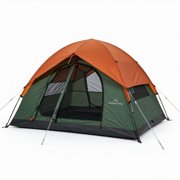
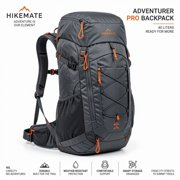
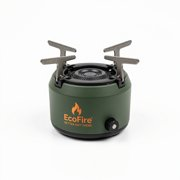
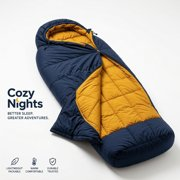
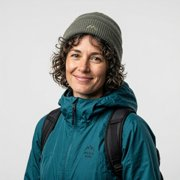

Full size: [tent](output/01-prop-tent.png) · [backpack](output/01-prop-backpack.png) · [stove](output/01-prop-stove.png) · [sleeping-bag](output/01-prop-sleeping-bag.png) · [hiker](output/01-prop-hiker.png)

In [3]:
PROPS = {
    "tent": f"Studio product photo on a plain white background: the {TENT}, {LOOK}, pitched, three-quarter front view.",
    "backpack": "Studio product photo on a plain white background: the Adventurer Pro Backpack by HikeMate, a 40-liter charcoal-grey hiking pack with orange zip pulls, a lid pocket and side mesh bottle pockets.",
    "stove": "Studio product photo on a plain white background: the EcoFire Camping Stove, a compact single-burner stove with a matte-green base, folding steel pot supports and a small orange EcoFire logo.",
    "sleeping-bag": "Studio product photo on a plain white background: the CozyNights Sleeping Bag, a navy mummy-style sleeping bag with a mustard-yellow lining, half unzipped.",
    "hiker": "Studio portrait on a plain light-grey background of a fictional hiker in her thirties with short curly hair, smiling, wearing a teal rain jacket and a knit beanie.",
}

with ThreadPoolExecutor(max_workers=5) as pool:
    jobs = {name: pool.submit(mai.generate, prompt, f"01-prop-{name}", FLASH) for name, prompt in PROPS.items()}
props = {name: job.result() for name, job in jobs.items()}
show(props, height=180)

**What to look for:** the details that make each product ours: orange zip pulls, green stove base, mustard lining. Routine shots like these are where Flash's speed pays off most.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Can we tell them apart blind?

Four prompts, each made by both models, shuffled into **A** and **B**: text on a hang tag, materials at night, an exact flat-lay, and a portrait.

> 🔮 **Guess first:** will we spot MAI-Image-2.6 every time?

   02-taste-text-flash: MAI-Image-2.6-Flash | 10.0 s | 1024×1024
   02-taste-materials-flash: MAI-Image-2.6-Flash | 10.2 s | 1024×1024
   02-taste-text-hero: MAI-Image-2.6 | 23.2 s | 1024×1024
   02-taste-instructions-flash: MAI-Image-2.6-Flash | 10.2 s | 1024×1024
   02-taste-materials-hero: MAI-Image-2.6 | 23.6 s | 1024×1024
   02-taste-portrait-flash: MAI-Image-2.6-Flash | 9.9 s | 1024×1024
   02-taste-instructions-hero: MAI-Image-2.6 | 26.1 s | 1024×1024
   02-taste-portrait-hero: MAI-Image-2.6 | 24.7 s | 1024×1024



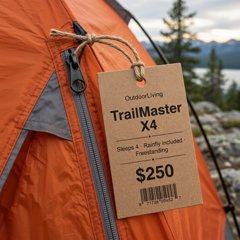
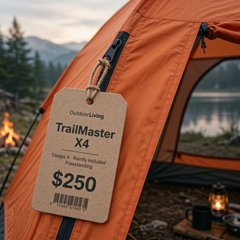

Full size: [text · A](output/02-taste-text-hero.png) · [text · B](output/02-taste-text-flash.png)


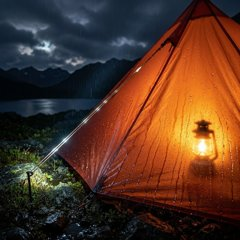
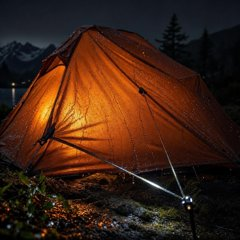

Full size: [materials · A](output/02-taste-materials-hero.png) · [materials · B](output/02-taste-materials-flash.png)


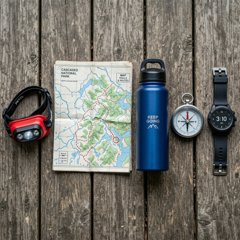
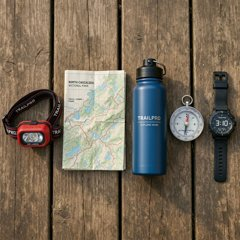

Full size: [instructions · A](output/02-taste-instructions-flash.png) · [instructions · B](output/02-taste-instructions-hero.png)


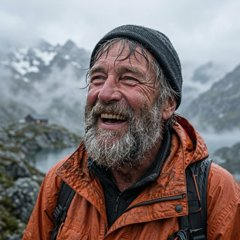
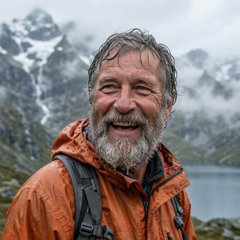

Full size: [portrait · A](output/02-taste-portrait-flash.png) · [portrait · B](output/02-taste-portrait-hero.png)

In [4]:
TASTE_TESTS = {
    "text": "A kraft-paper hang tag tied with twine to the zipper of an orange tent. Printed on it: 'OutdoorLiving' (small), 'TrailMaster X4' (large), 'Sleeps 4 · Rainfly included · Freestanding' (small), '$250' (bold), and a small barcode.",
    "materials": "Close-up of a burnt-orange tent rainfly at night, glowing from a lantern inside, rain beads shining on the fabric, and a reflective guyline catching a headlamp beam.",
    "instructions": "Overhead flat-lay on a wooden deck: exactly five items in one row, left to right: a red headlamp, a folded map, a blue water bottle, a compass whose needle points to the top of the image, and a wristwatch showing 3:10.",
    "portrait": "Portrait of a fictional mountain guide in his sixties, laughing, rain in his grey beard, wearing a faded orange jacket, soft overcast light, shallow depth of field.",
}
LABEL = {HERO: "hero", FLASH: "flash"}

with ThreadPoolExecutor(max_workers=8) as pool:
    jobs = {(test, model): pool.submit(mai.generate, prompt, f"02-taste-{test}-{LABEL[model]}", model)
            for test, prompt in TASTE_TESTS.items() for model in (HERO, FLASH)}
taste = {key: job.result() for key, job in jobs.items()}

shuffle = random.Random(2026)  # Fixed, so replay shows the same A and B every time
secret = {test: shuffle.sample([HERO, FLASH], 2) for test in TASTE_TESTS}
for test, (model_a, model_b) in secret.items():
    show({f"{test} · A": taste[(test, model_a)], f"{test} · B": taste[(test, model_b)]}, height=240)

Vote first: put `"A"` or `"B"` for the picture we like better in each test, then run the reveal.

In [5]:
votes = {"text": "", "materials": "", "instructions": "", "portrait": ""}

for test, (model_a, model_b) in secret.items():
    picked = {"A": model_a, "B": model_b}.get(votes[test].strip().upper(), "no vote yet")
    print(f"{test:>12}: A was {model_a}, B was {model_b} | we picked {picked}")

        text: A was MAI-Image-2.6, B was MAI-Image-2.6-Flash | we picked no vote yet
   materials: A was MAI-Image-2.6, B was MAI-Image-2.6-Flash | we picked no vote yet
instructions: A was MAI-Image-2.6-Flash, B was MAI-Image-2.6 | we picked no vote yet
    portrait: A was MAI-Image-2.6-Flash, B was MAI-Image-2.6 | we picked no vote yet


**What to look for:** where we *could* tell. Text and exact counts are where a quality gap usually shows first; materials and portraits are often closer than people expect.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. How much faster is Flash?

### Scoreboard

The typical (median) time per picture for each model in the taste test, from the run log. Speed depends on region, time of day, and prompt, so our own numbers are the ones to share. For cost, use the [pricing page](https://aka.ms/MAIModelPricing).

In [6]:
times = {model: [mai.log[f"02-taste-{test}-{LABEL[model]}"]["seconds"] for test in TASTE_TESTS] for model in (HERO, FLASH)}
for model, seconds in times.items():
    print(f"{model:22} median {statistics.median(seconds):5.1f} s   (range {min(seconds)}–{max(seconds)} s)")
ratio = statistics.median(times[FLASH]) / statistics.median(times[HERO])
print(f"\n{FLASH} took about {ratio:.0%} of the time {HERO} took. Both share the same requests-per-minute limit.")

MAI-Image-2.6          median  24.1 s   (range 23.2–26.1 s)
MAI-Image-2.6-Flash    median  10.1 s   (range 9.9–10.2 s)

MAI-Image-2.6-Flash took about 42% of the time MAI-Image-2.6 took. Both share the same requests-per-minute limit.


**What to look for:** the gap in our own run. Microsoft's launch post compares Flash with a different model, not with MAI-Image-2.6, so a measured comparison like this one is what to bring to a customer conversation.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Draft on Flash, finish on MAI-Image-2.6?

Explore six ad concepts on Flash, pick one, then hand it to MAI-Image-2.6 as a reference to finish it, keeping the idea.

> 🔮 **Guess first:** will the finished ad keep the draft's layout?

   03-draft-1: MAI-Image-2.6-Flash | 10.9 s | 1024×1024
   03-draft-2: MAI-Image-2.6-Flash | 10.3 s | 1024×1024
   03-draft-3: MAI-Image-2.6-Flash | 10.1 s | 1024×1024
   03-draft-4: MAI-Image-2.6-Flash | 11.3 s | 1024×1024
   03-draft-5: MAI-Image-2.6-Flash | 10.8 s | 1024×1024
   03-draft-6: MAI-Image-2.6-Flash | 9.5 s | 1024×1024



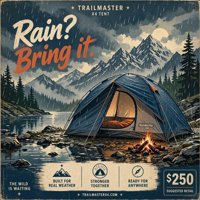
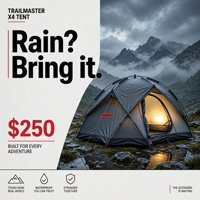
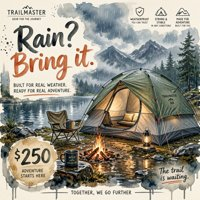
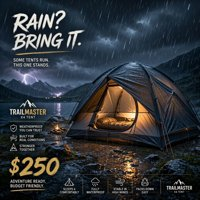
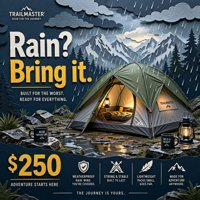
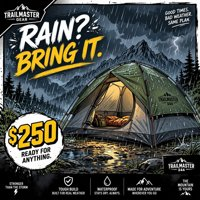

Full size: [Draft 1](output/03-draft-1.png) · [Draft 2](output/03-draft-2.png) · [Draft 3](output/03-draft-3.png) · [Draft 4](output/03-draft-4.png) · [Draft 5](output/03-draft-5.png) · [Draft 6](output/03-draft-6.png)

In [7]:
STYLES = ["a 1970s screen-printed national-park poster", "a bold minimal Swiss-style poster", "a cozy loose watercolor",
          "a cinematic night photo in heavy rain", "a layered papercut diorama", "a playful comic-book panel"]
AD = f'An ad for the {TENT} with the headline "Rain? Bring it." and the price "$250". Style: {{style}}.'

with ThreadPoolExecutor(max_workers=6) as pool:
    jobs = [pool.submit(mai.generate, AD.format(style=style), f"03-draft-{n}", FLASH) for n, style in enumerate(STYLES, start=1)]
drafts = [job.result() for job in jobs]
show({f"Draft {n}": path for n, path in enumerate(drafts, start=1)}, height=200)

Pick a favorite by number. Replay has a finished version of draft 1 only; live mode can finish any of them.

   03-final-from-draft-1: MAI-Image-2.6 | 23.2 s | 1024×1024



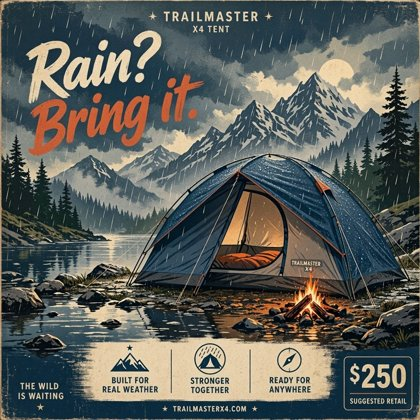
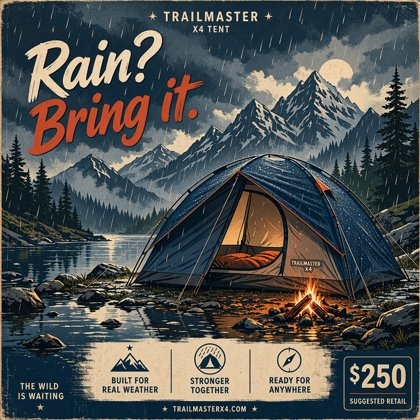

Full size: [Draft 1 · MAI-Image-2.6-Flash](output/03-draft-1.png) · [Final · MAI-Image-2.6](output/03-final-from-draft-1.png)

In [8]:
WINNER = 1

FINISH = """Re-create this concept as the final campaign image. Keep the same layout, style and idea.
Make the detail sharper, the lighting richer and the typography cleaner.
Spell the headline exactly "Rain? Bring it." and the price exactly "$250"."""

final_ad = mai.edit(FINISH, [drafts[WINNER - 1]], f"03-final-from-draft-{WINNER}", HERO)
show({f"Draft {WINNER} · {FLASH}": drafts[WINNER - 1], f"Final · {HERO}": final_ad}, height=420)

**What to look for:** the same layout and idea, with sharper detail and cleaner type, and the headline and price spelled exactly. Six drafts on Flash plus one finish on MAI-Image-2.6 usually costs less, and takes less waiting, than six drafts on MAI-Image-2.6.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

### 🔧 Break it on purpose

Edits take up to five reference images. What happens with six?

In [9]:
if MODE == "live":
    try:
        mai.edit("All six drafts as one poster wall.", drafts, "break-six-references", FLASH)
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 400 and says how many images it accepts.")

400 from MAI-Image-2.6-Flash. The model didn't accept a setting. Check the size (each side 768 or more, 2,359,296 pixels at most), the image type (PNG or JPEG), and the options.
Invalid request. Error => Only 1 to 5 image files are supported for edit requests.


The fix is to pick the five that matter most, or combine references first (for example, the 2×2 catalog page from [MAI-Image-2.6 · 01](../mai-image-2.6/mai-image-2.6-01-text-and-design.ipynb) counts as one image).

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Teach it to a customer

**Pick MAI-Image-2.6-Flash when:**

- We need many pictures: catalog backgrounds, ad variations, personal touches
- Someone is waiting, for example inside an app
- We're exploring ideas and drafts, or doing routine edits like cleanup

**Pick MAI-Image-2.6 when:**

- It's a hero picture people will study, or the final full-size version
- There's a lot of text on the picture, or close-ups need materials that look real
- We're combining several references into one scene

**Not sure? Use both:** draft on Flash, finish on MAI-Image-2.6.

**Four questions to ask:** how many pictures a day, is a person waiting for each one, is there text on the picture, and will it be seen as a thumbnail or on a billboard?

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Our own taste test.** Replace the four `TASTE_TESTS` prompts with four from a real catalog, and vote again.
- **Edits on Flash.** Run the three-step edit from [MAI-Image-2.6 · 02](../mai-image-2.6/mai-image-2.6-02-edit-and-compose.ipynb) on Flash. Do edits hold up as well?

In [10]:
# Your experiment here. Try: mai.generate("...", "my-picture", FLASH, size=(1024, 1024))

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Made five studio product shots on Flash
- ✅ Judged Flash against MAI-Image-2.6 blind, and measured the time each took
- ✅ Drafted six ad concepts on Flash and finished the favorite on MAI-Image-2.6

➡️ **Next:** see these product shots come to life in the [MiniMax H3 Max capsule](../fal-minimax-h3-max/), which puts all four products into one video scene.

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) · [Image Generation primer](../../3-primers/image-generation.md) · [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/)